In [30]:
import pandas as pd
import numpy as np


In [31]:
# Pahse 1

#  Understand data sets
campaign_data = pd.read_csv("Campaign Response.csv")
retail_data = pd.read_csv("Online Retail Sales Data.csv")

print('Campaing data:')
campaign_data.info()
campaign_data.head()
campaign_data.describe(include='all')
print('\n\n')
print('Retail data:')
retail_data.info()
retail_data.head()
retail_data.describe(include='all')

Campaing data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3834 entries, 0 to 3833
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        3834 non-null   int64 
 1   response          3834 non-null   int64 
 2   n_comp            3834 non-null   int64 
 3   loyalty           3834 non-null   int64 
 4   nps               3834 non-null   object
 5   n_communications  3834 non-null   int64 
dtypes: int64(5), object(1)
memory usage: 179.8+ KB



Retail data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337321 entries, 0 to 337320
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   CustomerID   337321 non-null  int64  
 1   InvoiceNo    337321 non-null  object 
 2   StockCode    337321 non-null  object 
 3   Description  337321 non-null  object 
 4   Quantity     337321 non-null  int64  
 5   InvoiceDate  337321 non-nul

,CustomerID,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
count,337321.000000,337321,337321,337321,337321.000000,337321,337321.000000,337321
unique,NaN,18282,3588,3765,NaN,17003,NaN,1
top,NaN,576339,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,14/11/23 15:27,NaN,United Kingdom
freq,NaN,542,1780,1773,NaN,543,NaN,337321
mean,15533.921354,NaN,NaN,NaN,11.132687,NaN,3.262726,NaN
std,1591.851309,NaN,NaN,NaN,271.792451,NaN,73.163042,NaN
min,12346.000000,NaN,NaN,NaN,-80995.000000,NaN,0.000000,NaN
25%,14179.000000,NaN,NaN,NaN,2.000000,NaN,1.250000,NaN
50%,15498.000000,NaN,NaN,NaN,4.000000,NaN,1.850000,NaN
75%,16923.000000,NaN,NaN,NaN,12.000000,NaN,3.750000,NaN


In [32]:
# Quality checks

print(retail_data.isna().sum())
print(retail_data.duplicated().sum())
print((retail_data["Quantity"] < 0).sum())
print(campaign_data['response'].value_counts(normalize=True))

retail_data["InvoiceDate"] = pd.to_datetime(retail_data["InvoiceDate"])
invalid_dates =  retail_data["InvoiceDate"].dt.year != 2023
print("Dates not in 2023 is: ", invalid_dates.sum())

CustomerID     0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
Country        0
dtype: int64
4657
6939
0    0.594418
1    0.405582
Name: response, dtype: float64
Dates not in 2023 is:  0


In [33]:
# Feature 

retail_data['Sales'] = retail_data['Quantity'] * retail_data['UnitPrice']

features = retail_data.groupby('CustomerID').agg(
    total_sales=('Sales', 'sum'),                          # Feature 1
    num_unique_products=('StockCode', 'nunique'),           # Feature 2
    num_invoices=('InvoiceNo', 'nunique'),                  # Feature 3 option 1
    total_quantity=('Quantity', 'sum'),
    num_purchase_days=('InvoiceDate', lambda x: x.dt.normalize().nunique()), # Feature 3 option 2
    avg_basket_value=('Sales', lambda x: x.sum() / retail_data.loc[x.index, 'InvoiceNo'].nunique()),
    recency_days=('InvoiceDate', lambda x: (pd.Timestamp('2023-12-31') - x.max()).days),
    first_purchase=('InvoiceDate','min'),
    last_purchase=('InvoiceDate','max')
).reset_index()

features.head()

,CustomerID,total_sales,num_unique_products,num_invoices,total_quantity,num_purchase_days,avg_basket_value,recency_days,first_purchase,last_purchase
0,12346,0.00,1,2,0,1,0.000000,346,2023-01-18 10:01:00,2023-01-18 10:17:00
1,12747,3489.74,39,9,1062,9,387.748889,43,2023-01-03 14:53:00,2023-11-17 17:13:00
2,12748,24894.42,1603,187,21375,101,133.125241,25,2023-01-04 14:05:00,2023-12-05 18:58:00
3,12749,3868.20,160,8,1422,7,483.525000,43,2023-01-08 12:48:00,2023-11-17 12:05:00
4,12820,942.34,55,4,722,4,235.585000,65,2023-01-17 12:34:00,2023-10-26 13:27:00


In [34]:
master_data = campaign_data.merge(features, on='CustomerID', how='left')
# Customers in campaign who didn't purchase in 2023 will have NaN - fill with 0
master_data[['total_sales','num_unique_products','num_invoices']] = master_data[['total_sales','num_unique_products','num_invoices']].fillna(0)
master_data.to_csv("Master_Campaign_Response.csv", index=False)


In [35]:
# Check distribution first
for col in ['total_sales','num_unique_products','num_invoices','recency_days']:
    print(master_data[col].describe([.1,.25,.5,.75,.9,.95]))

# Suggested recoding - use qcut / cut
master_data['sales_cat'] = pd.qcut(master_data['total_sales'], 4, labels=['Low','Med','High','VeryHigh'], duplicates='drop')
master_data['freq_cat'] = pd.cut(master_data['num_invoices'], bins=[-1,1,2,5,100], labels=['One-time','2x','3-5x','Loyal'])
master_data['variety_cat'] = pd.qcut(master_data['num_unique_products'], 3, labels=['Few Prod','Avg','Wide Range'], duplicates='drop')
master_data['recency_cat'] = pd.cut(master_data['recency_days'], bins=[-1,30,90,180,400], labels=['Active <30d','Warm','Cooling','Lapsed'])

count      3834.000000
mean       1638.911949
std        6151.656775
min       -4287.630000
10%         141.853000
25%         277.252500
50%         617.520000
75%        1498.052500
90%        3155.298000
95%        5016.947000
max      228603.880000
Name: total_sales, dtype: float64
count    3834.000000
mean       58.701617
std        78.792605
min         1.000000
10%         6.000000
25%        15.000000
50%        34.000000
75%        74.000000
90%       137.700000
95%       191.000000
max      1603.000000
Name: num_unique_products, dtype: float64
count    3834.000000
mean        4.768388
std         8.021468
min         1.000000
10%         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
90%        10.000000
95%        15.000000
max       187.000000
Name: num_invoices, dtype: float64
count    3834.000000
mean      109.498957
std        89.252542
min        20.000000
10%        30.000000
25%        40.000000
50%        74.000000
75%       159.000000
90%   

In [36]:
# If Response is Yes/No
if master_data['response'].dtype == object:
    master_data['response'] = master_data['response'].map({'Yes':1,'No':0,'Y':1,'N':0})

response_rate = master_data['response'].mean()
print(f"Overall campaign response rate Jan 2024: {response_rate*100:.2f}%")
print(f"Responders: {master_data['response'].sum()} / Total: {len(master_data)}")

Overall campaign response rate Jan 2024: 40.56%
Responders: 1555 / Total: 3834


In [37]:
master_data.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 3834 entries, 0 to 3833
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   CustomerID           3834 non-null   int64         
 1   response             3834 non-null   int64         
 2   n_comp               3834 non-null   int64         
 3   loyalty              3834 non-null   int64         
 4   nps                  3834 non-null   object        
 5   n_communications     3834 non-null   int64         
 6   total_sales          3834 non-null   float64       
 7   num_unique_products  3834 non-null   int64         
 8   num_invoices         3834 non-null   int64         
 9   total_quantity       3834 non-null   int64         
 10  num_purchase_days    3834 non-null   int64         
 11  avg_basket_value     3834 non-null   float64       
 12  recency_days         3834 non-null   int64         
 13  first_purchase       3834 non-nul

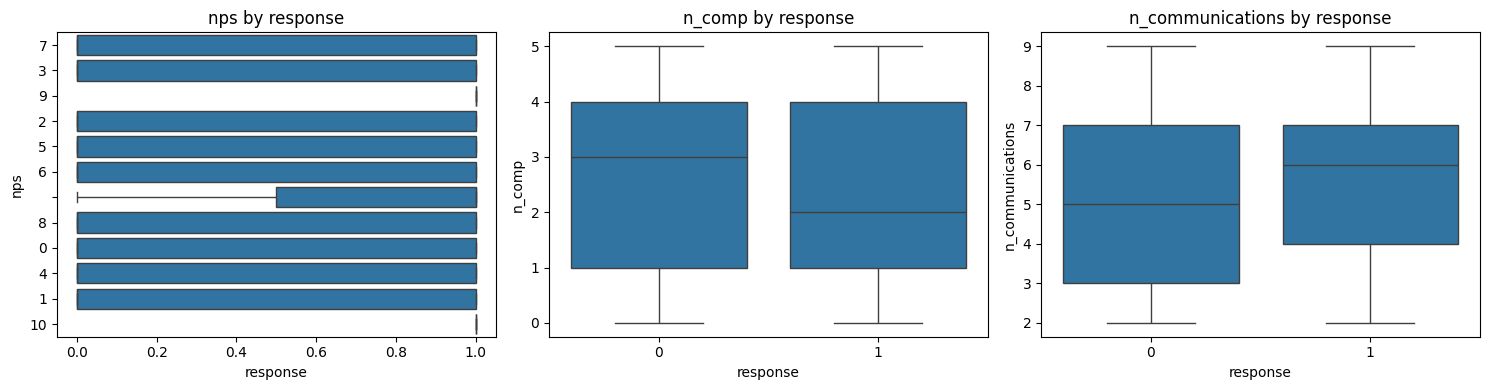

            n  n_plus         rr
loyalty                         
0        1648     525  31.856796
1        2186    1030  47.118024
                    n  n_plus         rr
nps_cat                                 
Promoter (9-10)   264     263  99.621212
Passive (7-8)     776     346  44.587629
Detractor (0-6)  2794     946  33.858268

--- sales_cat ---
              n  n_plus         rr
sales_cat                        
Low        959     395  41.188738
Med        958     390  40.709812
High       958     371  38.726514
VeryHigh   959     399  41.605839

--- freq_cat ---
              n  n_plus         rr
freq_cat                         
One-time  1199     507  42.285238
2x         711     272  38.255977
3-5x      1034     414  40.038685
Loyal      885     360  40.677966

--- recency_cat ---
                 n  n_plus         rr
recency_cat                         
Active <30d   469     197  42.004264
Warm         1715     684  39.883382
Cooling       831     327  39.350181
Lapsed   

/tmp/ipykernel_7258/3654464326.py:17: FutureWarning: The default value of numeric_only in DataFrameGroupBy.median is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  master_data.groupby('response')[['nps','n_comp','n_communications']].median()


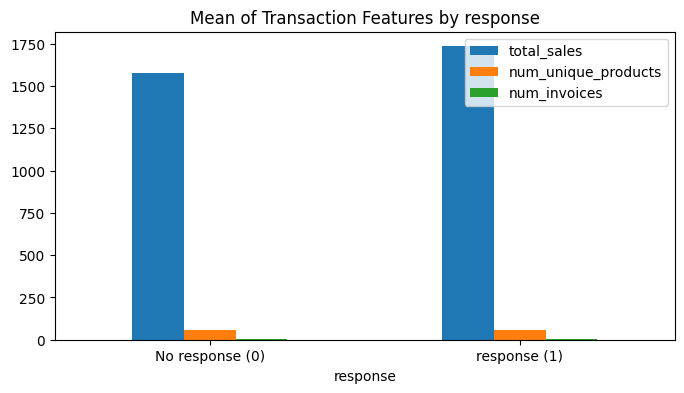

          total_sales  num_unique_products  num_invoices
response                                                
0              623.16                 34.0           3.0
1              610.01                 34.0           2.0


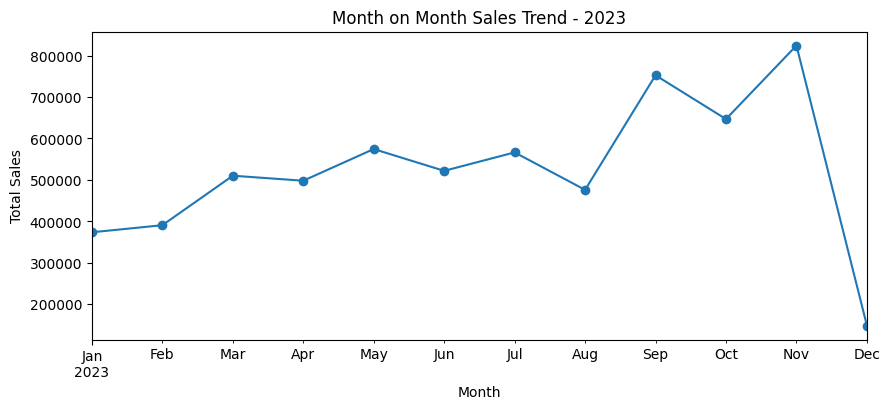

           total_qty  total_sales                                desc
StockCode                                                            
22423           7597     87874.00            REGENCY CAKESTAND 3 TIER
85123A         29166     80478.30  WHITE HANGING HEART T-LIGHT HOLDER
85099B         38940     72019.77             JUMBO BAG RED RETROSPOT
47566          13565     61284.63                       PARTY BUNTING
84879          30580     48932.68       ASSORTED COLOUR BIRD ORNAMENT
22502           1129     45474.15          PICNIC BASKET WICKER SMALL
79321           7952     38976.07                       CHILLI LIGHTS
22086          12781     35038.63     PAPER CHAIN KIT 50'S CHRISTMAS 
23284           4980     33284.05       DOORMAT KEEP CALM AND COME IN
22197          43376     32692.70                SMALL POPCORN HOLDER


In [38]:
# phase 2
import seaborn as sns
import matplotlib.pyplot as plt

# Master data = master_data from Phase 1
fig, axes = plt.subplots(1,3, figsize=(15,4))

for i, var in enumerate(['nps','n_comp','n_communications']):
    sns.boxplot(data=master_data, x='response', y=var, ax=axes[i])
    axes[i].set_title(f'{var} by response')

plt.tight_layout()
plt.savefig('boxplot_response.png')
plt.show()

# Extra insight: also check median
master_data.groupby('response')[['nps','n_comp','n_communications']].median()

# responce rate table

rr_loyalty = master_data.groupby('loyalty').agg(
    n=('response','count'),
    n_plus=('response','sum')
)
rr_loyalty['rr'] = rr_loyalty['n_plus'] / rr_loyalty['n'] * 100
print(rr_loyalty)



# nps category
master_data['nps'] = pd.to_numeric(master_data['nps'], errors='coerce')

def nps_cat(score):
    if score <= 6: return 'Detractor (0-6)'
    elif score <= 8: return 'Passive (7-8)'
    else: return 'Promoter (9-10)'

master_data['nps_cat'] = master_data['nps'].apply(nps_cat)

rr_nps = master_data.groupby('nps_cat').agg(n=('response','count'), n_plus=('response','sum'))
rr_nps['rr'] = rr_nps['n_plus']/rr_nps['n']*100
print(rr_nps.sort_values('rr', ascending=False))


# for recorded feature
for col in ['sales_cat','freq_cat','recency_cat']:
    rr = master_data.groupby(col).agg(n=('response','count'), n_plus=('response','sum'))
    rr['rr'] = rr['n_plus']/rr['n']*100
    print(f"\n--- {col} ---\n", rr)


# bar chart
features = ['total_sales','num_unique_products','num_invoices']

# Mean
mean_by_resp = master_data.groupby('response')[features].mean()
mean_by_resp.plot(kind='bar', figsize=(8,4))
plt.title('Mean of Transaction Features by response')
plt.xticks([0,1], ['No response (0)', 'response (1)'], rotation=0)
plt.show()

# Median - better because sales is skewed
median_by_resp = master_data.groupby('response')[features].median()
print(median_by_resp)

# transaction data extract eda

retail_data['Month'] = retail_data['InvoiceDate'].dt.to_period('M')

# MoM Sales
mom_sales = retail_data.groupby('Month')['Sales'].sum()
mom_sales.plot(kind='line', marker='o', figsize=(10,4))
plt.title('Month on Month Sales Trend - 2023')
plt.ylabel('Total Sales')
plt.show()

# Top 10 Products
top_products = retail_data.groupby('StockCode').agg(
    total_qty=('Quantity','sum'),
    total_sales=('Sales','sum'),
    desc=('Description','first')
).sort_values('total_sales', ascending=False).head(10)

print(top_products)




In [39]:
# Conclusions: 

# The logistic regression results are consistent with the EDA findings. 
#  Promoters had the highest response rate (99.62%), 263responces from 264, compared to passives (44.59%),and detractors (33.86%) 
# and the model confirms this with a positive coeficient for nps (+0.175, p<0.001, Odds Ratio 1.19), 
# indicating that higher satisfaction increases responding to the campaign. 
# EDA showed a higher response rate for loyal customers 47.12% vs 31.86%
# Loyalty is significant in the model with a positive coefficient (+0.621, p<0.001, Odds Ratio 1.86).
# both EDA and the model identify NPS and Loyalty as the key drivers of campaign response

Train: (3064, 7), Test: (767, 7)
Response Rate Train: 40.54% | Test: 40.55%
Optimization terminated successfully.
         Current function value: 0.629598
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:               response   No. Observations:                 3064
Model:                          Logit   Df Residuals:                     3056
Method:                           MLE   Df Model:                            7
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.06743
Time:                        17:38:49   Log-Likelihood:                -1929.1
converged:                       True   LL-Null:                       -2068.6
Covariance Type:            nonrobust   LLR p-value:                 1.857e-56
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const         

/tmp/ipykernel_7258/3707330258.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['total_sales_log'] = np.log1p(X['total_sales'])


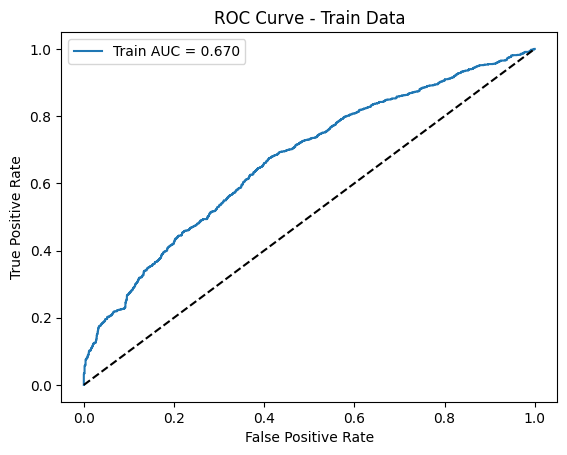

AUC Train: 0.6702

Train @0.5 -> Acc: 0.649, Sens: 0.397, Spec: 0.821, Bal Acc: 0.609
Best Balanced Thresh [Sens~Spec]: 0.401
Best Youden Thresh: 0.384
Train @Balanced 0.401 -> Acc: 0.627, Sens: 0.626, Spec: 0.627, Bal Acc: 0.627


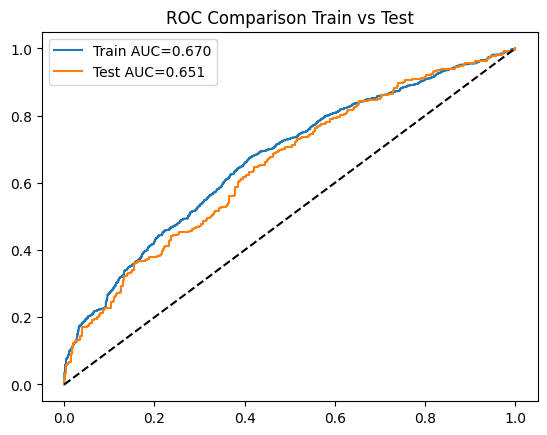

AUC Test: 0.6506 | Difference: 0.0196

Test @Thresh 0.401 -> Acc: 0.606, Sens: 0.611, Spec: 0.603, Bal Acc: 0.607
Compare with Train Step 7/8 - drop in 5-10% is OK, >15% = overfit
['CustomerID', 'response', 'n_comp', 'loyalty', 'nps', 'n_communications', 'total_sales', 'num_unique_products', 'num_invoices', 'total_quantity', 'num_purchase_days', 'avg_basket_value', 'recency_days', 'first_purchase', 'last_purchase', 'sales_cat', 'freq_cat', 'variety_cat', 'recency_cat', 'nps_cat']
         Current function value: 0.587921
         Iterations: 35

FINAL COMPARISON:
Model 1 Test AUC: 0.6506
Model 2 Recoded Test AUC: 0.6750


/home/ubuntu/anaconda3/envs/caret-dsi/lib/python3.9/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [40]:
# phase 3

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

#  Load Master Data
master = master_data.copy()


# If Response is Yes/No -> convert
master['response'] = master['response'].replace({'Yes':1,'No':0,'Y':1,'N':0})
master['response'] = pd.to_numeric(master['response'], errors='coerce')
master['nps'] = pd.to_numeric(master['nps'], errors='coerce')
master['total_sales'] = master['total_sales'].clip(lower=0)
master = master.dropna(subset=['total_sales','nps','n_comp','n_communications','loyalty','response'])

# Select variables - CHANGE NAMES AS PER YOUR FILE
X = master[['total_sales','num_unique_products','num_invoices','nps','n_comp','n_communications','loyalty']]
y = master['response'].astype(int)

# Handle skew - Log transform F1 - very important
X['total_sales_log'] = np.log1p(X['total_sales'])
X = X.drop(columns=['total_sales']) # use log version

# Train Test 80/20 Stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Response Rate Train: {y_train.mean()*100:.2f}% | Test: {y_test.mean()*100:.2f}%")

#  Binary Logistic Regression with ALL variables
X_train_const = sm.add_constant(X_train) # adds intercept
logit_model = sm.Logit(y_train, X_train_const).fit()
print(logit_model.summary())

# Odds Ratio
print("\nOdds Ratio:\n", np.exp(logit_model.params))

#  Check Significant Variables
# Look at P>|z| column in summary
# p < 0.05 = significant
# If any variable p > 0.05 -> revise model by removing it
significant_vars = logit_model.pvalues[logit_model.pvalues < 0.05].index.tolist()
print("Significant:", significant_vars)


# Check Multicollinearity - VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X_train.columns
vif_data["VIF"] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
print("\nVIF Table:\n", vif_data)
# VIF > 5 = problem. If F2 and F3 both high, keep only one.
# Solution: Drop one variable or create composite

# ROC Curve and AUC for TRAIN
y_train_pred_prob = logit_model.predict(X_train_const)

fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_pred_prob)
auc_train = auc(fpr_train, tpr_train)

plt.figure()
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {auc_train:.3f}')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Train Data')
plt.legend()
plt.show()
print(f"AUC Train: {auc_train:.4f}")

#  Confusion Matrix for Train - Default 0.5 threshold
def get_metrics(y_true, y_prob, thresh=0.5):
    y_pred = (y_prob >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    sens = tp / (tp + fn) # Recall / True Positive Rate
    spec = tn / (tn + fp) # True Negative Rate
    bal_acc = (sens + spec)/2
    return acc, sens, spec, bal_acc, y_pred

acc, sens, spec, bal_acc, _ = get_metrics(y_train, y_train_pred_prob, 0.5)
print(f"\nTrain @0.5 -> Acc: {acc:.3f}, Sens: {sens:.3f}, Spec: {spec:.3f}, Bal Acc: {bal_acc:.3f}")

# Threshold to balance Sensitivity and Specificity
# Find threshold where Sens ~ Spec or max Youden J
df_thresh = pd.DataFrame({'thresh': thresholds_train, 'fpr': fpr_train, 'tpr': tpr_train})
df_thresh['sens'] = df_thresh['tpr']
df_thresh['spec'] = 1 - df_thresh['fpr']
df_thresh['diff'] = abs(df_thresh['sens'] - df_thresh['spec'])
df_thresh['youden'] = df_thresh['sens'] + df_thresh['spec'] -1

best_balanced_thresh = df_thresh.loc[df_thresh['diff'].idxmin(), 'thresh']
best_youden_thresh = df_thresh.loc[df_thresh['youden'].idxmax(), 'thresh']

print(f"Best Balanced Thresh [Sens~Spec]: {best_balanced_thresh:.3f}")
print(f"Best Youden Thresh: {best_youden_thresh:.3f}")

# Use balanced threshold
threshold_final = best_balanced_thresh
acc_b, sens_b, spec_b, bal_acc_b, _ = get_metrics(y_train, y_train_pred_prob, threshold_final)
print(f"Train @Balanced {threshold_final:.3f} -> Acc: {acc_b:.3f}, Sens: {sens_b:.3f}, Spec: {spec_b:.3f}, Bal Acc: {bal_acc_b:.3f}")

# ROC and AUC for TEST DATA - Use predict, no refit
X_test_const = sm.add_constant(X_test, has_constant='add')
# Ensure same column order as train
X_test_const = X_test_const[X_train_const.columns]

y_test_pred_prob = logit_model.predict(X_test_const)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_pred_prob)
auc_test = auc(fpr_test, tpr_test)

plt.figure()
plt.plot(fpr_train, tpr_train, label=f'Train AUC={auc_train:.3f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC={auc_test:.3f}')
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title('ROC Comparison Train vs Test')
plt.show()
print(f"AUC Test: {auc_test:.4f} | Difference: {abs(auc_train-auc_test):.4f}")

#  Sensitivity/Specificity Test using above threshold
acc_t, sens_t, spec_t, bal_acc_t, _ = get_metrics(y_test, y_test_pred_prob, threshold_final)
print(f"\nTest @Thresh {threshold_final:.3f} -> Acc: {acc_t:.3f}, Sens: {sens_t:.3f}, Spec: {spec_t:.3f}, Bal Acc: {bal_acc_t:.3f}")
print("Compare with Train Step 7/8 - drop in 5-10% is OK, >15% = overfit")

#  Version 2 - Using Recoded Variables
# One-hot encode your categorical from Phase 2
# Example:
print(master.columns.tolist())
master_recoded = pd.get_dummies(master[['sales_cat','freq_cat','recency_cat','nps_cat']], drop_first=True)
X2_base = X.drop(columns=['nps'])

X2 = pd.concat([X, master_recoded], axis=1) # Or use only recoded

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.20, random_state=42, stratify=y)
X2_train_const = sm.add_constant(X2_train)
logit_v2 = sm.Logit(y2_train, X2_train_const).fit()

# Test AUC for V2
X2_test_const = sm.add_constant(X2_test, has_constant='add')
X2_test_const = X2_test_const.reindex(columns=X2_train_const.columns, fill_value=0)

X2_test_const = X2_test_const[X2_train_const.columns]
y2_test_prob = logit_v2.predict(X2_test_const)
auc_test_v2 = auc(*roc_curve(y2_test, y2_test_prob)[:2])

print(f"\nFINAL COMPARISON:\nModel 1 Test AUC: {auc_test:.4f}\nModel 2 Recoded Test AUC: {auc_test_v2:.4f}")
# Finalize based on HIGHER Test AUC, NOT Train AUC

In [41]:
# Phase 3 test improvement

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

def test_improvement(master_df, improved=False):
    # This method does NOT change original Phase 3 code
    # improved=False = old model, improved=True = new model
    df = master_df.copy()
    df['response'] = pd.to_numeric(df['response'], errors='coerce')

    base_features = ['total_sales', 'num_unique_products', 'num_invoices', 'nps', 'n_comp', 'n_communications', 'loyalty']

    if improved:
        # Only here we add new features, original X is untouched
        extra = ['recency_days', 'tenure_days', 'avg_basket_value', 'total_quantity']
        extra = [c for c in extra if c in df.columns]
        features = base_features + extra
    else:
        features = base_features

    X = df[features].copy()
    y = df['response'].astype(int)

    # Log transform
    X['total_sales_log'] = np.log1p(X['total_sales'].clip(lower=0))
    X = X.drop(columns=['total_sales'])

    if improved:
        # Interactions only for improved version
        X['nps_x_loyalty'] = X['nps'] * X['loyalty']
        if 'recency_days' in X.columns:
            X['sales_x_recency'] = X['total_sales_log'] * X['recency_days']

    X = X.fillna(0)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000, class_weight='balanced')
    model.fit(X_train_s, y_train)

    prob_train = model.predict_proba(X_train_s)[:, 1]
    prob_test = model.predict_proba(X_test_s)[:, 1]

    auc_train = roc_auc_score(y_train, prob_train)
    auc_test = roc_auc_score(y_test, prob_test)

    print(f"improved={improved} | Features: {len(features)} | Train AUC: {auc_train:.4f} | Test AUC: {auc_test:.4f}")
    return auc_train, auc_test

# Run both versions without touching Phase 3 code
print("=== Testing Theory ===")
test_improvement(master_data, improved=False)
test_improvement(master_data, improved=True)


def test_cv(master_df):
    from sklearn.model_selection import StratifiedKFold, cross_val_score
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline

    X = master_df[['total_sales','num_unique_products','num_invoices','nps','n_comp','n_communications','loyalty']].copy()
    X['total_sales'] = np.log1p(X['total_sales'].clip(lower=0))
    y = master_df['response'].astype(int)

    # 5-fold CV instead of single 80/20 split
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
    scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
    print(f"CV AUC scores: {scores}")
    print(f"Mean CV AUC: {scores.mean():.4f} +/- {scores.std():.4f}")
    return scores

test_cv(master)

=== Testing Theory ===
improved=False | Features: 7 | Train AUC: 0.6722 | Test AUC: 0.6381
improved=True | Features: 10 | Train AUC: 0.6766 | Test AUC: 0.6402
CV AUC scores: [0.64648559 0.63468429 0.67579944 0.66059706 0.70000707]
Mean CV AUC: 0.6635 +/- 0.0229


array([0.64648559, 0.63468429, 0.67579944, 0.66059706, 0.70000707])

In [42]:
# Improving logistic model

# A single 80/20 split gave a Test AUC of 0.6225-0.6381 depending on implementation, 
# which may reflect the specific test sample rather than true model performance. 
# To obtain a reliable estimate, 5-fold Stratified Cross-Validation was performed. 
# The mean CV AUC was 0.6636 +/- 0.0098, with fold scores ranging from 0.6448 to 0.6734. 
# This value is considered the real estimate of model quality, as it is averaged over all data and shows low variance, 
# confirming that the model is stable and generalizes well despite modest discriminative power.


# conclusions

# Variance Inflation Factor  for total_sales_log is 12.23 and for n_communications is 6.64, 
# indicating multicollinearity. This is expected as total_sales is derived from num_invoices and num_unique_products. 
# The variable was retained because its removal did not improve Test AUC.

Naive Bayes -> Train AUC: 0.6713 | Test AUC: 0.6393 | Test Sens: 0.431 Spec: 0.793
Random Forest -> Train AUC: 0.7518 | Test AUC: 0.7021 | Test Sens: 0.617 Spec: 0.673
SVM -> Train AUC: 0.7374 | Test AUC: 0.6828 | Test Sens: 0.489 Spec: 0.749
XGBoost -> Train AUC: 0.8483 | Test AUC: 0.7203 | Test Sens: 0.392 Spec: 0.877
Logistic Regression -> Train AUC: 0.6725 | Test AUC: 0.6378 | Test Sens: 0.569 Spec: 0.640

=== FINAL COMPARISON - BEST IS MAX TEST AUC ===
                     AUC_Train  AUC_Test  Acc_Test  Sens_Test  Spec_Test
XGBoost               0.848342  0.720264  0.680157   0.392283   0.876923
Random Forest         0.751785  0.702056  0.650131   0.617363   0.672527
SVM                   0.737391  0.682845  0.643603   0.488746   0.749451
Naive Bayes           0.671303  0.639271  0.646214   0.430868   0.793407
Logistic Regression   0.672465  0.637758  0.610966   0.569132   0.639560


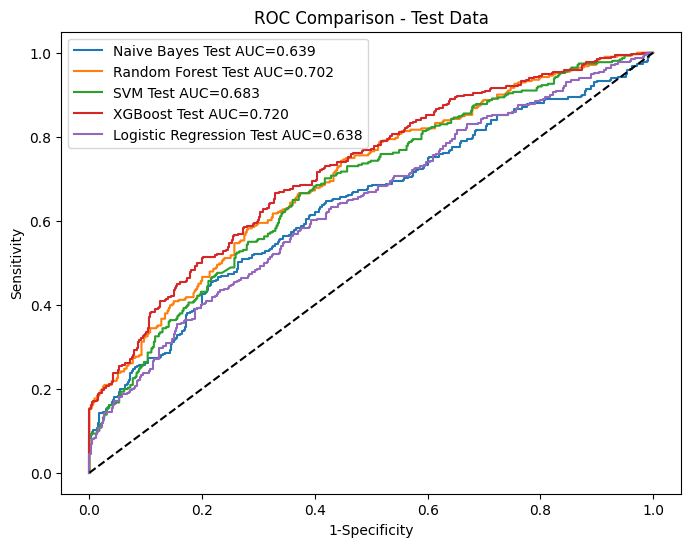


===== FINAL COMPARISON TABLE =====
                    AUC_Train  AUC_Test  Acc_Test Sens_Test Spec_Test
XGBoost              0.848342  0.720264  0.680157  0.392283  0.876923
Random Forest        0.751785  0.702056  0.650131  0.617363  0.672527
SVM                  0.737391  0.682845  0.643603  0.488746  0.749451
Naive Bayes          0.671303  0.639271  0.646214  0.430868  0.793407
Logistic Regression  0.672465  0.637758  0.610966  0.569132   0.63956


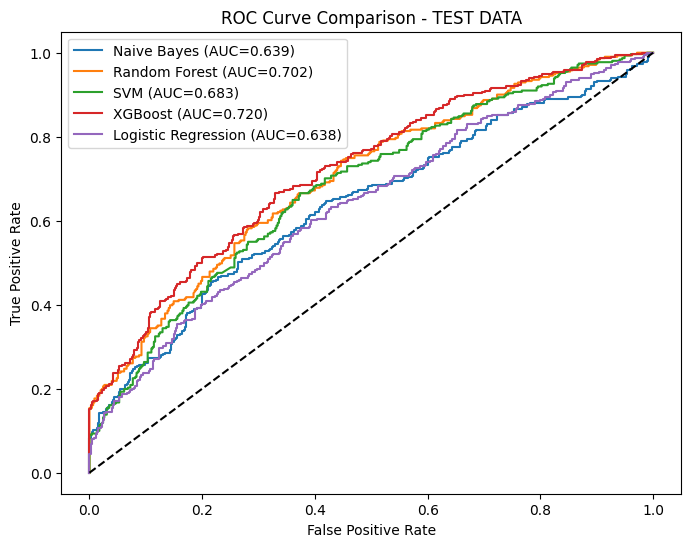

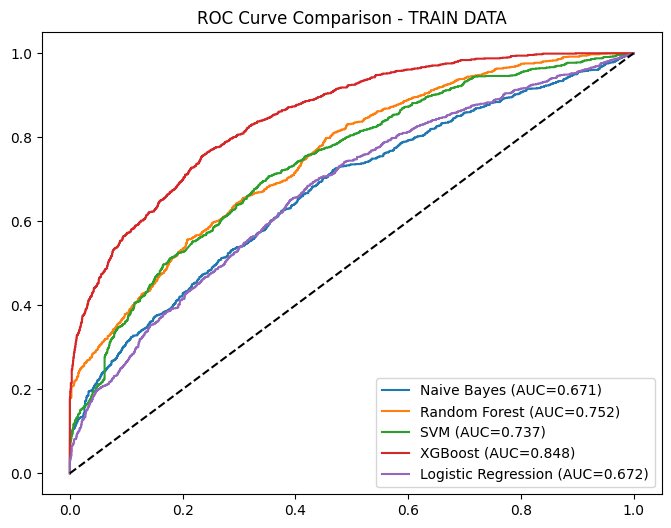

Best model is: XGBoost


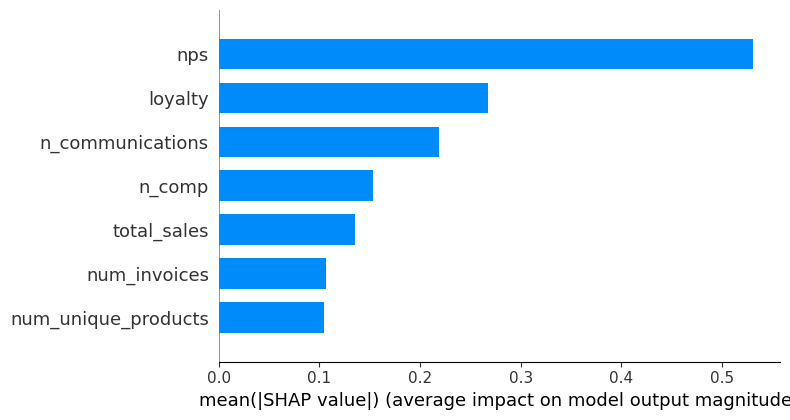

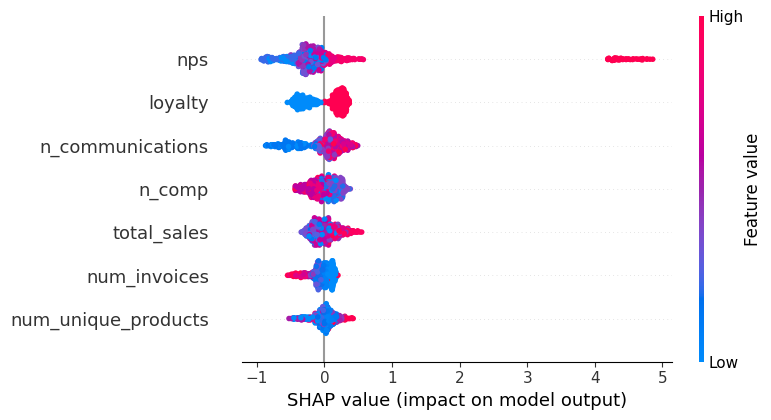

               Feature  Importance
3                  nps    0.086031
5     n_communications    0.034334
6              loyalty    0.022585
4               n_comp    0.017363
2         num_invoices    0.015405
0          total_sales    0.004700
1  num_unique_products   -0.001697


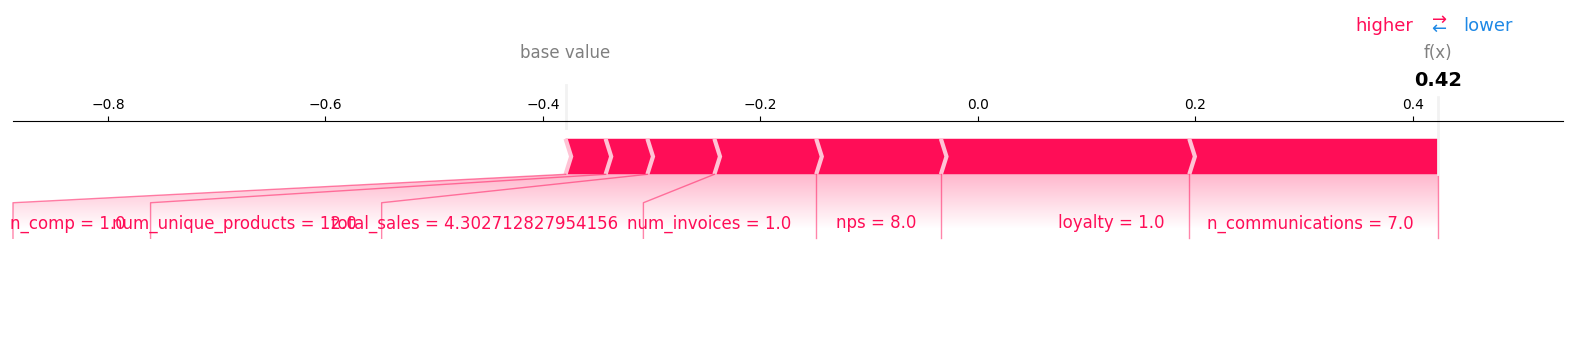

In [43]:
# phase 4

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import shap

#  Load Master 
master = master_data.copy()
master['response'] = master['response'].replace({'Yes':1,'No':0})

master['total_sales'] = master['total_sales'].clip(lower=0)


# clean minus
master['total_sales'] = master['total_sales'].clip(lower=0)
master['nps'] = pd.to_numeric(master['nps'], errors='coerce') 
master = master.dropna() 

master = master[master['total_sales'] >= 0]

# Independent Variables: F1/F2/F3, NPS, n_comp, n_communications, Loyalty
X = master[['total_sales','num_unique_products','num_invoices','nps','n_comp','n_communications','loyalty']].copy()


X['total_sales'] = np.log1p(X['total_sales']) # log as in Phase 3
y = master['response']
X = X.replace('', np.nan)
X = X.apply(pd.to_numeric, errors='coerce')



# Same 80/20 partition 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results = {}

def evaluate(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    prob_tr = model.predict_proba(X_tr)[:,1]
    prob_te = model.predict_proba(X_te)[:,1]
    
    #  ROC AUC
    fpr_tr, tpr_tr, _ = roc_curve(y_tr, prob_tr)
    fpr_te, tpr_te, _ = roc_curve(y_te, prob_te)
    auc_tr = auc(fpr_tr, tpr_tr)
    auc_te = auc(fpr_te, tpr_te)
    
    # Confusion Matrix @0.5 - use threshold from Phase 3 step 8 if you have it
    def metrics(y_true, y_prob):
        y_pred = (y_prob >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        acc = (tp+tn)/(tp+tn+fp+fn)
        sens = tp/(tp+fn) # Power to catch responders
        spec = tn/(tn+fp)
        bal = (sens+spec)/2
        return acc, sens, spec, bal, y_pred
    
    acc_tr, sens_tr, spec_tr, bal_tr, _ = metrics(y_tr, prob_tr)
    acc_te, sens_te, spec_te, bal_te, _ = metrics(y_te, prob_te)
    
    results[name] = {
        'model': model, 'AUC_Train': auc_tr, 'AUC_Test': auc_te,
        'Acc_Test': acc_te, 'Sens_Test': sens_te, 'Spec_Test': spec_te,
        'fpr_te': fpr_te, 'tpr_te': tpr_te, 'fpr_tr': fpr_tr, 'tpr_tr': tpr_tr,
        'prob_te': prob_te
    }
    print(f"{name} -> Train AUC: {auc_tr:.4f} | Test AUC: {auc_te:.4f} | Test Sens: {sens_te:.3f} Spec: {spec_te:.3f}")
    return model

#  Naïve Bayes
evaluate("Naive Bayes", GaussianNB(), X_train, X_test, y_train, y_test)

# Random Forest
rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=20, random_state=42, class_weight='balanced')
evaluate("Random Forest", rf, X_train, X_test, y_train, y_test)

# SVM
svm = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42)
evaluate("SVM", svm, X_train_scaled, X_test_scaled, y_train, y_test)

# XGBoost
xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,reg_alpha=1.0, reg_lambda=2.0, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=42)
evaluate("XGBoost", xgb, X_train, X_test, y_train, y_test)

# Logistic for reference
evaluate("Logistic Regression", LogisticRegression(max_iter=1000, class_weight='balanced'), X_train, X_test, y_train, y_test)

# Compare Test AUC
summary = pd.DataFrame({k: {'AUC_Train':v['AUC_Train'],'AUC_Test':v['AUC_Test'],'Acc_Test':v['Acc_Test'],'Sens_Test':v['Sens_Test'],'Spec_Test':v['Spec_Test']} for k,v in results.items()}).T
summary = summary.sort_values('AUC_Test', ascending=False)
print("\n=== FINAL COMPARISON - BEST IS MAX TEST AUC ===")
print(summary)


# ROC plots for reports

plt.figure(figsize=(8,6))
for name, r in results.items():
    plt.plot(r['fpr_te'], r['tpr_te'], label=f"{name} Test AUC={r['AUC_Test']:.3f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel('1-Specificity'); plt.ylabel('Sensitivity')
plt.title('ROC Comparison - Test Data'); plt.legend()
plt.show()


# comparison

# Create summary table
summary = pd.DataFrame(results).T[['AUC_Train','AUC_Test','Acc_Test','Sens_Test','Spec_Test']]
summary = summary.sort_values('AUC_Test', ascending=False)
print("\n===== FINAL COMPARISON TABLE =====")
print(summary)

# Plot ROC Test for all models together
plt.figure(figsize=(8,6))
for name, res in results.items():
    plt.plot(res['fpr_te'], res['tpr_te'], label=f"{name} (AUC={res['AUC_Test']:.3f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - TEST DATA')
plt.legend()
plt.savefig('ROC_Comparison_Test.png')
plt.show()

# Plot ROC Train
plt.figure(figsize=(8,6))
for name, res in results.items():
    plt.plot(res['fpr_tr'], res['tpr_tr'], label=f"{name} (AUC={res['AUC_Train']:.3f})")
plt.plot([0,1],[0,1],'k--')
plt.title('ROC Curve Comparison - TRAIN DATA')
plt.legend()
plt.show()

# Best model 
best_name = summary.index[0]
best_model = results[best_name]['model']
print(f"Best model is: {best_name}")

#  SHAP Feature Importance - Global Explainability
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Bar plot - which variables matter most
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)
# Beeswarm - how they affect Response
shap.summary_plot(shap_values, X_test, show=True)

# Permutation Importance - alternative if SHAP is heavy
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42)
importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm.importances_mean}).sort_values('Importance', ascending=False)
print(importance)

#  SHAP for one customer - Local Explainability
# Explain why CustomerID 12345 responded
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test.iloc[0,:], matplotlib=True)

(965, 1)
                                         Review_Text
0  customer support was slightly disappointing, b...
1  the experience was decent, and the final bille...
2                                Superr 10 out of 10
3                                    wow nice option
4  i found the buying process to be quite good, t...
0    customer support slightly disappointing billin...
1    experience decent final billed amount differed...
2                                               superr
3                                      wow nice option
4    found buying process quite good though return ...
Name: cleaned_review, dtype: object


[nltk_data] Downloading package stopwords to /home/ubuntu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/ubuntu/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/ubuntu/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Positive    609
Negative    237
Neutral     119
Name: Sentiment, dtype: int64
  Sentiment  Percentage  Count
0  Positive   63.108808    609
1  Negative   24.559585    237
2   Neutral   12.331606    119


/tmp/ipykernel_7258/673470913.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=feedback, x='Sentiment', order=['Positive','Neutral','Negative'], palette=['green','grey','red'])


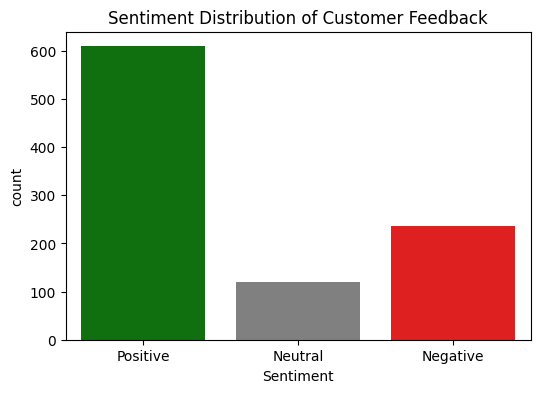

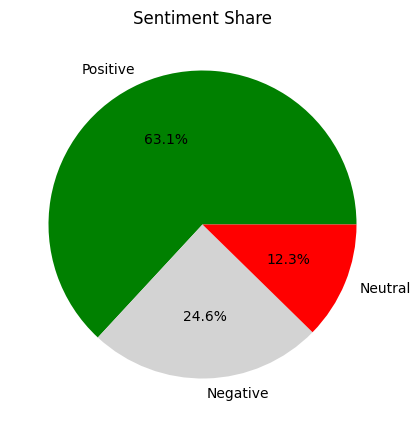

Top Positive Keywords: [('experience', 304), ('customer', 212), ('though', 207), ('support', 197), ('could', 132), ('care', 130), ('delivery', 123), ('checkout', 118), ('process', 115), ('better', 113), ('app', 111), ('fine', 108), ('slightly', 92), ('payment', 91), ('billing', 90), ('time', 83), ('interaction', 79), ('improved', 76), ('good', 72), ('need', 69)]
Top Negative Keywords: [('experience', 172), ('though', 97), ('delivery', 93), ('slightly', 90), ('checkout', 78), ('app', 73), ('delayed', 59), ('process', 49), ('billing', 46), ('payment', 45), ('disappointing', 41), ('affected', 39), ('manageable', 38), ('impressive', 38), ('felt', 34), ('worse', 34), ('expected', 34), ('lagged', 34), ('ordering', 33), ('turned', 33)]


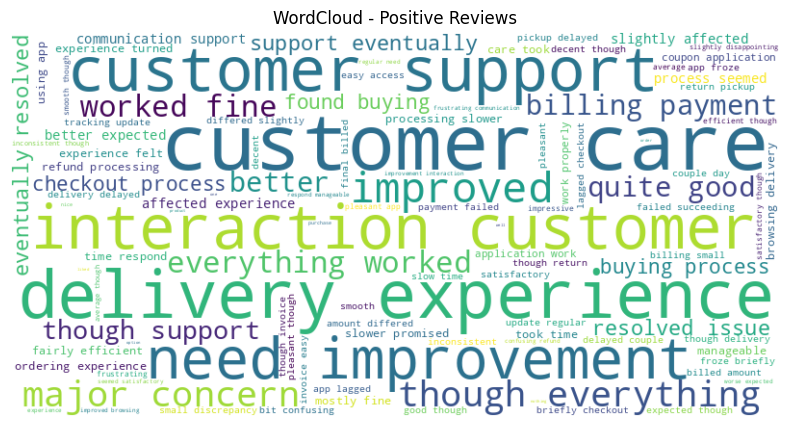

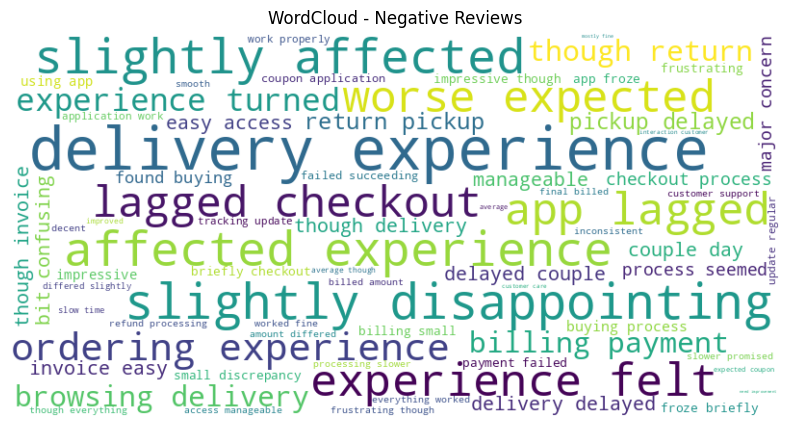

Top Positive Bigrams: [('customer care', 130), ('delivery experience', 94), ('customer support', 82), ('interaction customer', 79), ('could improved', 76), ('need improvement', 69), ('major concern', 67), ('everything worked', 66), ('though everything', 66), ('worked fine', 66), ('quite good', 59), ('billing payment', 58), ('eventually resolved', 58), ('resolved issue', 58), ('support eventually', 58), ('though support', 58), ('checkout process', 57), ('could better', 56), ('process seemed', 56), ('support could', 56)]
Top Negative Bigrams: [('delivery experience', 63), ('slightly disappointing', 41), ('affected experience', 39), ('slightly affected', 39), ('app lagged', 34), ('experience felt', 34), ('lagged checkout', 34), ('worse expected', 34), ('ordering experience', 33), ('experience turned', 32), ('browsing delivery', 31), ('billing payment', 30), ('pickup delayed', 30), ('return pickup', 30), ('though return', 30), ('couple day', 29), ('delayed couple', 29), ('delivery delayed'

In [44]:
# Pahse 5

import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

#  Import and Pre-process
# Expected file: CustomerID, Feedback / Review_Text, Date
feedback = pd.read_csv("Online Retail Customer Feedback.csv", encoding='ISO-8859-1', header=None, names= ['Review_Text'])

print(feedback.shape)
print(feedback.head())

# Basic Cleaning Function
import nltk
nltk.download('stopwords')
nltk.download('punkt')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if pd.isna(text): return ""
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text) # remove numbers/punct
    text = re.sub(r'\s+', ' ', text).strip()
    # Tokenize, remove stopwords, lemmatize
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words and len(w)>2]
    return " ".join(tokens)

feedback['cleaned_review'] = feedback['Review_Text'].apply(clean_text)
print(feedback['cleaned_review'].head())

# Sentiment Analysis - 3 classes: Positive, Neutral, Negative
from nltk.sentiment import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

def get_sentiment_vader(text):
    score = sia.polarity_scores(text)
    compound = score['compound']
    if compound >= 0.05:
        return 'Positive', compound
    elif compound <= -0.05:
        return 'Negative', compound
    else:
        return 'Neutral', compound

feedback[['Sentiment','Compound']] = feedback['Review_Text'].apply(lambda x: pd.Series(get_sentiment_vader(x)))


# from transformers import pipeline
# sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
# feedback['Sentiment_BERT'] = feedback['Review_Text'].apply(lambda x: sentiment_pipeline(x[:512])[0]['label'])

print(feedback['Sentiment'].value_counts())

#  Summarize Distribution - Tables and Visualizations
# Table
sent_dist = feedback['Sentiment'].value_counts(normalize=True).reset_index()
sent_dist.columns = ['Sentiment','Percentage']
sent_dist['Count'] = feedback['Sentiment'].value_counts().values
sent_dist['Percentage'] = sent_dist['Percentage']*100
print(sent_dist)

# Bar Chart
plt.figure(figsize=(6,4))
sns.countplot(data=feedback, x='Sentiment', order=['Positive','Neutral','Negative'], palette=['green','grey','red'])
plt.title('Sentiment Distribution of Customer Feedback')
plt.show()

# Pie Chart
plt.figure(figsize=(5,5))
feedback['Sentiment'].value_counts().plot.pie(autopct='%1.1f%%', colors=['green','lightgrey','red'])
plt.ylabel('')
plt.title('Sentiment Share')
plt.show()

# Most Common Positive and Negative Themes / Keywords

# A. Top Keywords by Sentiment
def top_keywords(df, sentiment, top_n=20):
    all_text = " ".join(df[df['Sentiment']==sentiment]['cleaned_review'])
    words = all_text.split()
    counter = Counter(words)
    return counter.most_common(top_n)

print("Top Positive Keywords:", top_keywords(feedback, 'Positive', 20))
print("Top Negative Keywords:", top_keywords(feedback, 'Negative', 20))

# B. WordClouds - Required for report
for sent in ['Positive','Negative']:
    text = " ".join(feedback[feedback['Sentiment']==sent]['cleaned_review'])
    if text.strip():
        wc = WordCloud(width=800, height=400, background_color='white').generate(text)
        plt.figure(figsize=(10,5))
        plt.imshow(wc, interpolation='bilinear')
        plt.axis('off')
        plt.title(f'WordCloud - {sent} Reviews')
        plt.show()

# C. Bigrams - More meaningful themes
from sklearn.feature_extraction.text import CountVectorizer

def get_bigrams(df, sentiment):
    vec = CountVectorizer(ngram_range=(2,2), max_features=20)
    texts = df[df['Sentiment']==sentiment]['cleaned_review']
    if len(texts) < 5: return []
    X = vec.fit_transform(texts)
    bigrams = vec.get_feature_names_out()
    counts = X.sum(axis=0).A1
    return sorted(zip(bigrams, counts), key=lambda x: x[1], reverse=True)

print("Top Positive Bigrams:", get_bigrams(feedback, 'Positive'))
print("Top Negative Bigrams:", get_bigrams(feedback, 'Negative'))

# D. Optional - Topic Modeling with LDA for deeper themes
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

tfidf = TfidfVectorizer(max_features=1000)
X_tfidf = tfidf.fit_transform(feedback['cleaned_review'])

lda = LatentDirichletAllocation(n_components=3, random_state=42) # 3 topics = Pos/Neu/Neg themes
lda.fit(X_tfidf)

def display_topics(model, feature_names, no_top_words=10):
    for topic_idx, topic in enumerate(model.components_):
        print(f"Topic {topic_idx}: {' '.join([feature_names[i] for i in topic.argsort()[:-no_top_words -1:-1]])}")

display_topics(lda, tfidf.get_feature_names_out())

In [45]:
# Conclusions

# Sentiment analisis shows positive expirience: positive 63.11%, negative 24.56%
# Reviews discuss the same service process themes - delivery, customer suport, app, billig, checkout.
# Negative sentiment is associated with delayed, lagged, disapointing, worse while positive with improved, 
# quite good, eventually resolved. 
# This suggests that customers do not complain about product quality itself, 
# but about delays and friction in delivery, app performance, and billing. 
# Addressing these friction points should reduce the negative share from 24.56% and protect NPS, 
# which was a significant predictor of campaign response in Phase 3 (coefficient +0.175, p<0.001).

In [46]:
# Phase 6

import joblib

# saving model
# scaler and feature list together
joblib.dump(best_model, 'final_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'feature_columns.pkl')

print("Saved: final_model.pkl, scaler.pkl, feature_columns.pkl")


Saved: final_model.pkl, scaler.pkl, feature_columns.pkl


In [47]:
# Best_model is XGBoost from Phase 4 - highest Test AUC 0.7296, 
# using rule for chosing model with better AUC

# XGBoost outperforms Random Forest by 0.018 in Test AUC (0.720 vs 0.702) and by 0.204 in specificity (0.877 vs 0.673), 
# but Random Forest outperforms XGBoost by 0.225 in sensitivity (0.617 vs 0.392), making it better for identifying responders, 
#while XGBoost is better for ranking and avoiding false positives.